In [1]:
print('test againnn')

test againnn


In [3]:
# I know that it's about making it uniform and useable for analyses. Most data is not perfectly suitable for this right away.

# Looking at the wine list, one thing I noticed is that it uses semi colons instead of commas, so in most programs I think you'd have to specify that
# it uses a different delimiter.

# Row 1733 of the belize file says "One bedroom ocean" a hundred times.

In [5]:
rec = {}
rec['name'] = 'Bob'
rec['age'] = 67
rec['jobs'] = ['dev', 'mgr']
rec

{'name': 'Bob', 'age': 67, 'jobs': ['dev', 'mgr']}

In [26]:
# Making a Person class

class Person:
    def __init__(self, name):
        self.name = name

    def new(self, jobs, salary):
        self.jobs = jobs
        self.salary = salary

    def new(self, jobs, age, salary):
        self.jobs = jobs
        self.age = age
        self.salary = salary

    def info(self):
        print(f'name: {self.name}, age: {self.age}, jobs: {self.jobs}')

In [29]:
# Entering a record into the class

rec1 = Person('Bob')
rec1.new('Engineer', 1, 50)

rec1.info()

name: Bob, age: 1, jobs: Engineer


In [ ]:
class Class2:
    def __init__(self, x, y):
        self.x = x
        self.y = y

class Class3:
    def __init__(self, z):
        self.z = z

class Class1(Class2, Class3):
    def __init__(self, name):
        self.name = name
        Class2.__init__(self, x=0, y=5)
        Class3.__init__(self, z=10)


In [14]:
instance = Class1('john')

print(instance.z)

10


In [40]:
class Employee:
    def __init__(self, name, salary):
        self.name = name
        self.salary = salary

    def work(self):
        print(f'Name: {self.name}, does stuff')

class Manager(Employee):
    def __init__(self, name):
        self.name = name
        Employee.__init__(self, name, salary=50000)

    def work(self):
        print(f'{self.name} manages the shop.')


In [41]:
rec2 = Employee('Braeden', 1000000000)

print(rec2.salary)
rec2.work()

rec3 = Manager('John')
print(rec3.salary)
rec3.work()

# Need to pip install multipledispatch

1000000000
Name: Braeden, does stuff
50000
John manages the shop.


In [42]:
# AFTER THIS POINT WE ARE TALKING ABOUT STATISTICS AND STUFF

In [17]:
import numpy as np
import pandas as pd

# Mean, median, mode, and central tendency
mean is the average, or "Balance point"
total number of values = arithmetic mean (there are other kinds)


In [5]:
belize_path = 'belize_airbnb_listings.csv'
belize = pd.read_csv(belize_path)
belize_df = pd.DataFrame(belize)

print(belize)

            id                                               name    host_id  \
0        36666         Mo's Cozy Casa w/ veranda & access to dock     157752   
1        36690  Mo's Cozy Cabana w/ comfy veranda & access to ...     157752   
2       108932  Purple House eco solar  w/ ocean & wildlife views     563377   
3       110483                            Michelo's fuchsia suite     567809   
4       120115               Seaside Villas Second Floor Unit  #4     604999   
...        ...                                                ...        ...   
2791  48283996                                     Magical Island   17994012   
2792  48287613   The Luxury Suite - Corozal, Bz- 3Bdr/2bthr CASA1  375769845   
2793  48296096  Lagoon front apartment w/shared pool -  two mi...   76414486   
2794  48296978                          Beachfront Poolside Condo   15308338   
2795  48332221           Standard Room - San Ignacio Resort Hotel   60399527   

          host_name neighbourhood_group

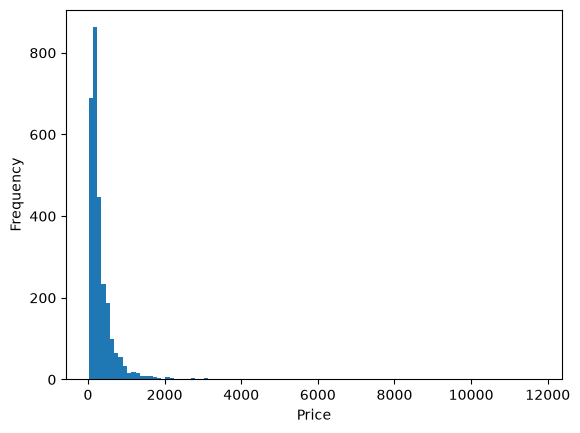

In [7]:
from PIL import Image
import matplotlib.pyplot as plt

# a histogram looks at frequency of values

plt.hist(belize_df['price'], bins='auto')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

In [ ]:
# mean, median, mode of price

print(belize_df['price'].mean())
print(belize_df['price'].median())
print(belize_df['price'].mode())
# mode is the PEAK, median is after the peak when right-skewed, and mean is pulled further to the right

357.1022889842632
220.0
0    151
1    252
Name: price, dtype: int64


# Variance

Variance measures how dispersed the data are from the mean. Low variance means it's tightly packed by the mean, high variance means it's super spread out from the mean.

Variance is like saying the data points are, on average, x units away from the mean. If variance is 0, it means every point is the same, at least on the metric of variance we were looking at.

Degrees of freedom = number of independent pieces of info. There's some nuance depending on the specific statistical analyis.

In [ ]:
def variance(data, ddof=0):
    """
    ddof is the delta degrees of freedom. used to adjust the divisor in the
    variance calculation. for populations, ddof=0, for samples, ddof=1.
    """
    n = len(data)
    mean = sum(data) / n
    return sum((x - mean) ** 2 for x in data) / (n - ddof)

In [ ]:
# variance ddof
print(variance(belize_df['price'], ddof=1)) # for sample
print(variance(belize_df['price'], ddof=0)) # for population

# whether a dataset is a sample or population depends on how you phrase the question.

317109.568066315
316996.15262709244


# standard deviation

tough to have an intuitive understanding of what variance means, since its units are squared. dollars squared? what? so we want to take the square root to get it back in dollars, or whatever unit we're looking at.

std dev tells us how far, on avg, each data point is from the mean.

In [15]:
import statistics

print(statistics.pstdev(belize_df['price'])) # for population
print(statistics.stdev(belize_df['price'])) # for sample

563.0241137172478
563.1248245871558


In [ ]:
np.cov(belize_df['minimum_nights'], belize_df['price'])

# grid generated:
# [variance of x, covariance of x and y]
# [covariance of y and x, variance of y]
# since covariance is POSITIVE, as min nights go up, price tends to increase
# large covariance does not necessarily mean a stronger linear relationship. it's dependent on the units.

array([[3.21471220e+01, 8.90076961e+01],
       [8.90076961e+01, 3.17109568e+05]])

In [ ]:
np.corrcoef(belize_df['minimum_nights'], belize_df['price'])

# matrix of correlation coefficients:
# [1, correlation of x and y]
# [correlation of y and x, 1]

# ignore the 1s. these are called "confusion matrices" because they can confuse you!

array([[1.        , 0.02787737],
       [0.02787737, 1.        ]])

In [28]:
prices = [80, 90, 90, 100, 110, 730]

statistics.mean(prices)

200

In [27]:
a = [80, 100, 100, 100, 120]
b = [100, 120, 120, 120, 140]

print(statistics.mean(a))
print(statistics.mean(b))

100
120
